# Reaction kinetics: discovering rate laws from batch data

Given noisy concentration-versus-time data from a batch reactor, can we recover
the rate laws? This is SINDy applied to chemical kinetics. The main lesson of
this notebook is that **the derivative estimate matters as much as the
regression**.

The dataset (`scripts/make_reaction_data.py`) is a liquid-phase batch reactor
run from six initial conditions, with two reactions:

- `A + B -> C`, rate `r1 = k1 C_A C_B` (bimolecular, k1 = 0.5)
- `C -> D`, rate `r2 = k2 C_C` (first order, k2 = 0.2)

so the true mole balances are

- `dCA/dt = dCB/dt = -k1 CA CB`
- `dCC/dt = k1 CA CB - k2 CC`
- `dCD/dt = k2 CC`

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from jax_ibart.datasets import DATA_DIR, load_reaction
from jax_ibart.dynamics import discover_ode

df = pd.read_csv(DATA_DIR / "reaction_kinetics.csv").sort_values(["batch", "t"])
species = ["CA", "CB", "CC", "CD"]
batches = sorted(df.batch.unique())
print(df.shape, "rows;", len(batches), "batches of", len(df) // len(batches), "time points")
df.head()

(360, 6) rows; 6 batches of 60 time points


,batch,t,CA,CB,CC,CD
0,0,0.000000,2.001257,1.998679,0.006404,0.001049
1,0,0.101695,1.810028,1.819001,0.195731,0.011396
2,0,0.203390,1.654934,1.649318,0.324597,0.007611
3,0,0.305085,1.509217,1.530280,0.439871,0.007879
4,0,0.406780,1.416244,1.418524,0.556974,0.035881


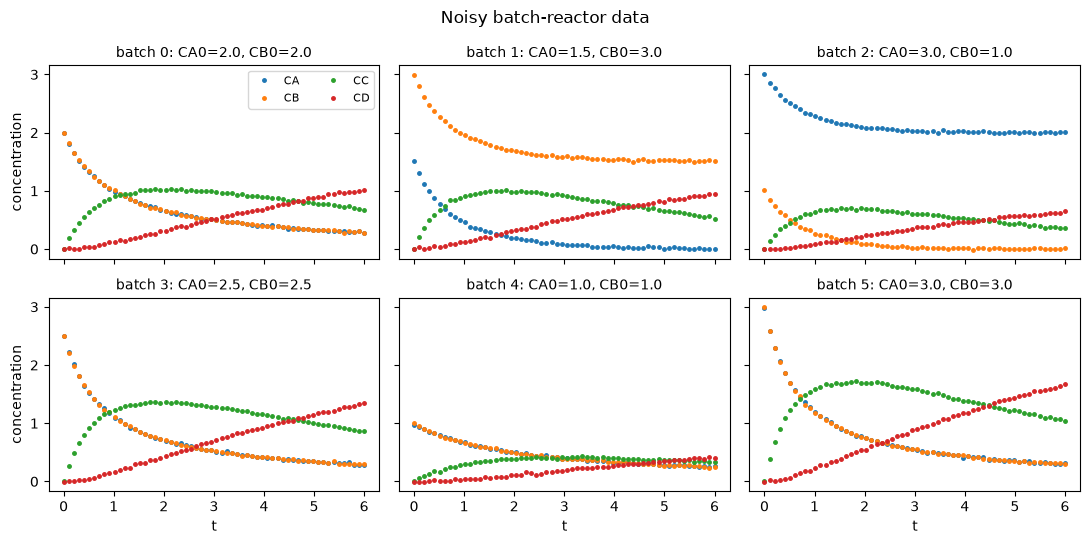

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, sharey=True)
for ax, b in zip(axes.flat, batches):
    g = df[df.batch == b]
    for s in species:
        ax.plot(g.t, g[s], "o", ms=2.5, label=s)
    ax.set_title(f"batch {b}: CA0={g.CA.iloc[0]:.1f}, CB0={g.CB.iloc[0]:.1f}", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("t")
for ax in axes[:, 0]:
    ax.set_ylabel("concentration")
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Noisy batch-reactor data")
fig.tight_layout()
plt.show()

## Attempt 1: finite-difference derivatives

`load_reaction` returns the concentrations and central finite-difference
derivatives computed within each batch. We fit each mole balance with at most
two library terms, and use the BART screen (`screen="bart"`) to prune the
library first.

In [3]:
C, dCdt_fd, _, batch = load_reaction()
fd = discover_ode(C, t=None, feature_names=species, dXdt=dCdt_fd,
                  degree=2, max_terms=2, screen="bart", seed=0)
print(fd)

dCA/dt = -0.4804*CA*CB - 0.008945  (R^2=0.974)
dCB/dt = -0.4876*CA*CB - 0.006196  (R^2=0.978)
dCC/dt = 0.4694*CA*CB + 0.04062*CA - 0.1882  (R^2=0.956)
dCD/dt = 0.1916*CC + 0.009089  (R^2=0.517)


`dCA/dt` and `dCB/dt` come out right (about `-0.48 CA CB`), and `dCD/dt` has
the right term (`0.19 CC`) but a poor R^2. `dCC/dt` is wrong: it has the
`CA CB` term but not `-0.2 CC`, with a constant offset in its place.

The plot below shows why. Finite differences amplify the measurement noise: with
a time step of 0.1 and noise of about 0.02, the derivative noise is about 0.13,
as large as the `0.2 CC` term we are trying to see.

## Attempt 2: smoothed derivatives

A Savitzky-Golay filter fits a local cubic polynomial in a sliding window and
differentiates it. That is much less noisy than a finite difference.

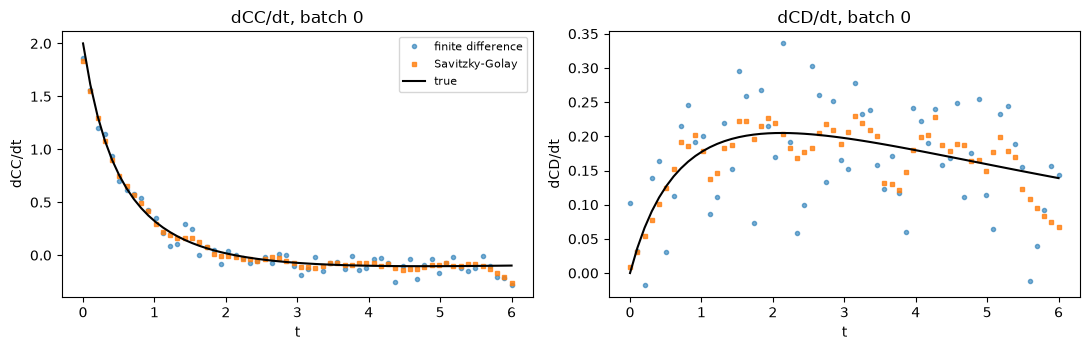

In [4]:
from scipy.signal import savgol_filter

parts = []
for b in batches:
    g = df[df.batch == b]
    dt = g.t.iloc[1] - g.t.iloc[0]
    parts.append(savgol_filter(g[species].to_numpy(), 11, 3, deriv=1, delta=dt,
                               axis=0, mode="interp"))
dCdt_sg = np.vstack(parts)

# true derivatives for batch 0, from the known model, for reference
def true_rhs(t, c, k1=0.5, k2=0.2):
    r1, r2 = k1 * c[0] * c[1], k2 * c[2]
    return [-r1, -r1, r1 - r2, r2]

g0 = df[df.batch == batches[0]]
t0 = g0.t.to_numpy()
ref = solve_ivp(true_rhs, [t0[0], t0[-1]], [2.0, 2.0, 0.0, 0.0], t_eval=t0, rtol=1e-8)
true_d = np.array([true_rhs(0, c) for c in ref.y.T])

m0 = batch == batches[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, i in zip(axes, [2, 3]):
    ax.plot(t0, dCdt_fd[m0, i], "o", ms=3, alpha=0.6, label="finite difference")
    ax.plot(t0, dCdt_sg[m0, i], "s", ms=3, alpha=0.8, label="Savitzky-Golay")
    ax.plot(t0, true_d[:, i], "k-", lw=1.5, label="true")
    ax.set_xlabel("t")
    ax.set_ylabel(f"d{species[i]}/dt")
    ax.set_title(f"d{species[i]}/dt, batch {batches[0]}")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [5]:
sg = discover_ode(C, t=None, feature_names=species, dXdt=dCdt_sg,
                  degree=2, max_terms=2, seed=0)
print(sg)
print("\ntrue: dCA/dt = -0.5 CA CB ; dCB/dt = -0.5 CA CB ; "
      "dCC/dt = 0.5 CA CB - 0.2 CC ; dCD/dt = 0.2 CC")

dCA/dt = -0.4863*CA*CB - 0.01496*CA*CC + 0.002667  (R^2=0.995)
dCB/dt = -0.4862*CA*CB - 0.01662*CA*CC + 0.003675  (R^2=0.995)
dCC/dt = 0.4793*CA*CB - 0.1822*CC - 0.007629  (R^2=0.992)
dCD/dt = 0.2023*CC - 0.001894  (R^2=0.900)

true: dCA/dt = -0.5 CA CB ; dCB/dt = -0.5 CA CB ; dCC/dt = 0.5 CA CB - 0.2 CC ; dCD/dt = 0.2 CC


With smoothed derivatives all four rate laws have the right terms, and the rate
constants are within about 10% of the true values. (The small extra terms in
`dCA/dt` and `dCB/dt` have coefficients below 0.02.)

We left out the BART screen this time. Here is what happens with it:

In [6]:
sg_bart = discover_ode(C, t=None, feature_names=species, dXdt=dCdt_sg,
                       degree=2, max_terms=2, screen="bart", seed=0)
print(sg_bart)

dCA/dt = -0.488*CA*CB - 0.005386  (R^2=0.995)
dCB/dt = -0.4881*CA*CB - 0.005275  (R^2=0.995)
dCC/dt = 0.01685*CA**2 + 0.4764*CA*CB - 0.1773  (R^2=0.975)
dCD/dt = 0.2023*CC - 0.001894  (R^2=0.900)


The screen drops `CC` from the `dCC/dt` library: `-0.2 CC` is a small
contribution next to `0.5 CA CB`, and a term the screen misses cannot be
recovered by the l0 fit afterwards. For a library this small (15 terms) the
screen is unnecessary; it earns its keep when the library is large. Either way,
check the result against the data, as below.

## Do the discovered rate laws reproduce the data?

The real test is to integrate the discovered ODEs from each batch's first
measurement and compare the trajectories with the data.

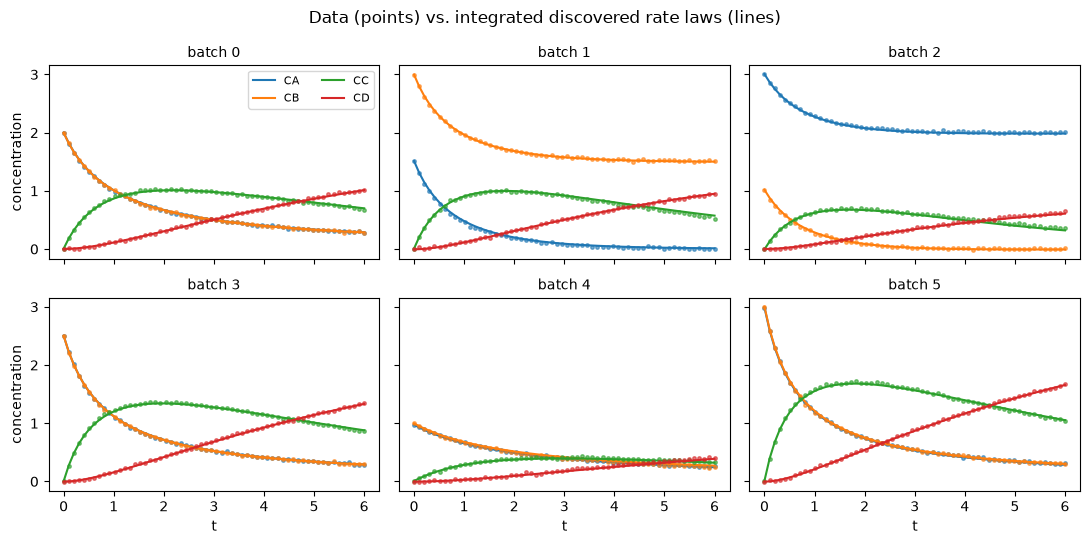

In [7]:
syms = sp.symbols("CA CB CC CD")
funcs = [sp.lambdify(syms, e, "numpy") for e in sg.rhs]

def learned(t, c):
    return [float(f(*c)) for f in funcs]

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, sharey=True)
for ax, b in zip(axes.flat, batches):
    g = df[df.batch == b]
    tb = g.t.to_numpy()
    sim = solve_ivp(learned, [tb[0], tb[-1]], g[species].iloc[0].to_numpy(),
                    t_eval=tb, rtol=1e-8)
    for k, s in enumerate(species):
        ax.plot(tb, g[s], "o", ms=2.5, color=f"C{k}", alpha=0.6)
        ax.plot(tb, sim.y[k], "-", color=f"C{k}", lw=1.5, label=s)
    ax.set_title(f"batch {b}", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("t")
for ax in axes[:, 0]:
    ax.set_ylabel("concentration")
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Data (points) vs. integrated discovered rate laws (lines)")
fig.tight_layout()
plt.show()

The discovered model reproduces all six batches, including the rise and fall of
the intermediate `C`.

Further steps for real kinetic data:

- a weak (integral) formulation avoids differentiating noisy data at all
  (Messenger & Bortz 2021, see [references](../references.md));
- passing `units=...` restricts the library to terms with consistent units;
- the [uncertainty tools](08_uncertainty.ipynb) show how stable the selected
  terms are under resampling.